# Credit Risk Analytics & Loan Default Prediction

## Stage 4 — Predictive Modelling

This stage develops and evaluates machine-learning models for predicting customer default.

The modelling approach prioritises both predictive performance and interpretability. Because the dataset is imbalanced, model performance will be assessed using metrics including precision, recall, F1-score and ROC-AUC rather than relying solely on accuracy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Load prepared datasets
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nMissing values:", X_train.isnull().sum().sum())

X_train: (23972, 29)
X_test: (5993, 29)
y_train: (23972,)
y_test: (5993,)

Missing values: 0


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [3]:
# Generate predictions

y_pred_log = logistic_model.predict(X_test)
y_prob_log = logistic_model.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_log), 4))
print("Precision:", round(precision_score(y_test, y_pred_log), 4))
print("Recall:", round(recall_score(y_test, y_pred_log), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_log), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_log), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.7442
Precision: 0.4431
Recall: 0.6078
F1 Score: 0.5126
ROC-AUC: 0.7528

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      4667
           1       0.44      0.61      0.51      1326

    accuracy                           0.74      5993
   macro avg       0.66      0.70      0.67      5993
weighted avg       0.78      0.74      0.76      5993



In [4]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [5]:
# Random Forest predictions

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.7672
Precision: 0.4794
Recall: 0.6056
F1 Score: 0.5352
ROC-AUC: 0.7757

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4667
           1       0.48      0.61      0.54      1326

    accuracy                           0.77      5993
   macro avg       0.68      0.71      0.69      5993
weighted avg       0.79      0.77      0.78      5993



In [6]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7442,0.4431,0.6078,0.5126,0.7528
1,Random Forest,0.7672,0.4794,0.6056,0.5352,0.7757


In [7]:
# Extract Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
24,MAX_DELAY,0.138984
5,PAY_0,0.128791
23,NUM_DELAYED_MONTHS,0.125251
6,PAY_2,0.056598
27,UTILISATION,0.037900
26,AVG_PAY_AMT,0.037625
7,PAY_3,0.036076
0,LIMIT_BAL,0.030003
25,AVG_BILL_AMT,0.029842
8,PAY_4,0.029325


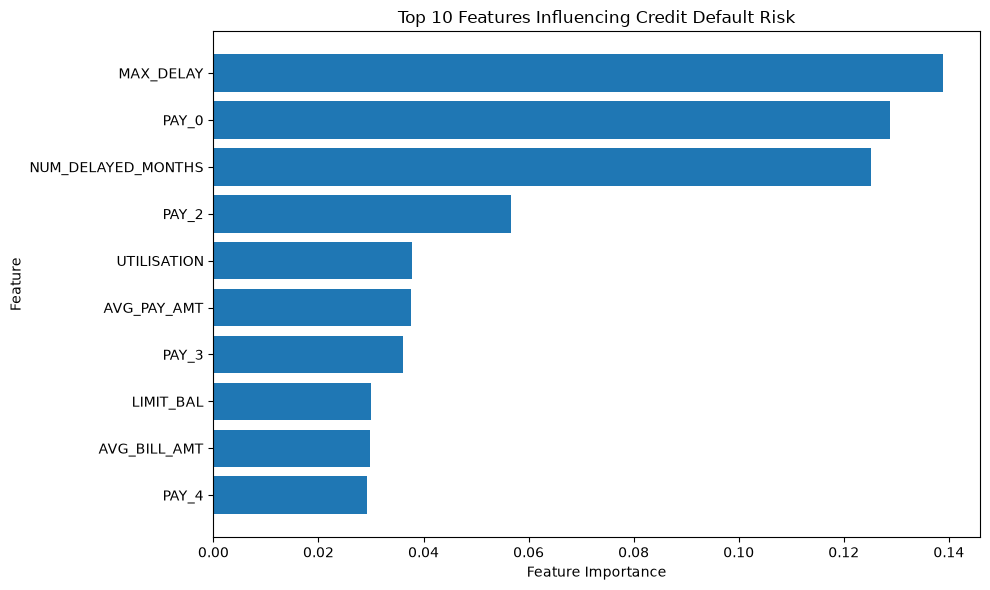

In [8]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Credit Default Risk")

plt.tight_layout()
plt.show()

### Random Forest Feature Importance — Risk Interpretation

The Random Forest model indicates that repayment behaviour is particularly important when predicting credit default risk.

The three most influential features were **MAX_DELAY**, **PAY_0**, and **NUM_DELAYED_MONTHS**. This suggests that both the severity and frequency of previous payment delays contain useful information when identifying customers with elevated default risk.

Other influential variables included credit utilisation, average payment amount, credit limit and average bill amount, indicating that the model also considers customers' broader financial behaviour.

From a risk-management perspective, these findings suggest that repayment history should be an important component of credit-risk assessment. However, feature importance measures how useful a variable was to the model and does not demonstrate that the variable directly causes default.

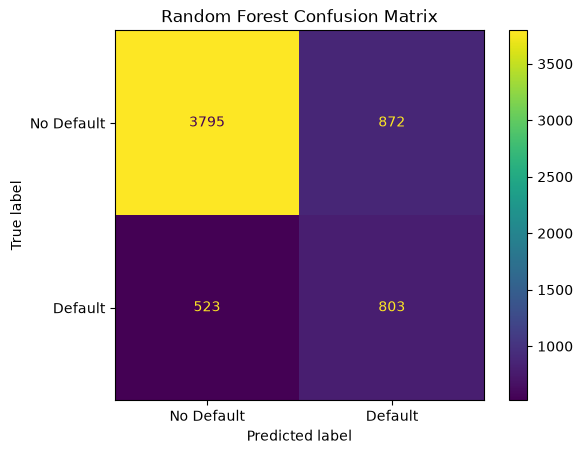

True Negatives: 3795
False Positives: 872
False Negatives: 523
True Positives: 803


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

# Print the values
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

### Confusion Matrix — Risk Interpretation

The Random Forest correctly classified **3,795 non-defaulting customers** and successfully identified **803 customers who defaulted**.

However, the model produced **872 false positives**, where customers were classified as likely to default despite not defaulting, and **523 false negatives**, where customers who actually defaulted were predicted as non-defaulting.

From a credit-risk perspective, false negatives are particularly important because they represent customers whose default risk was not detected by the model. The model identified approximately **60.6% of actual defaults**, meaning there remains scope to improve its ability to detect higher-risk customers.

This demonstrates why model performance should not be assessed using accuracy alone. Recall, precision, false-positive rates and false-negative rates should also be considered when evaluating a credit-risk model.

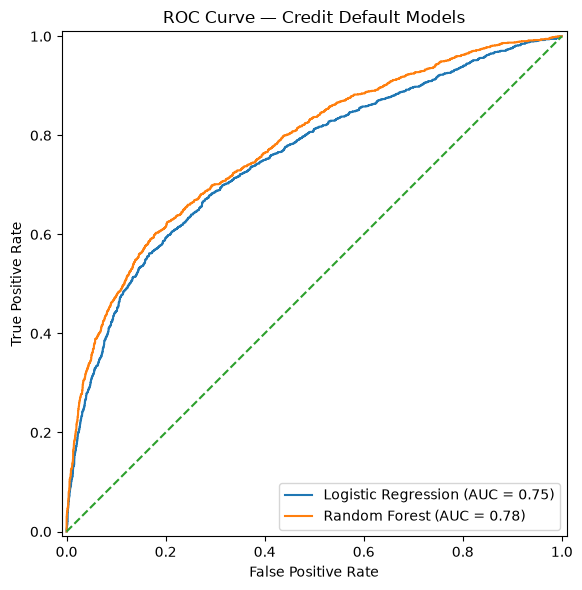

In [10]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_log,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest",
    ax=ax
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve — Credit Default Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.tight_layout()
plt.show()

### ROC Curve Interpretation

The ROC curves show that both models perform substantially better than random classification when distinguishing between customers who default and those who do not.

The **Random Forest achieved an ROC-AUC of approximately 0.78**, compared with approximately **0.75 for Logistic Regression**. This indicates that the Random Forest has a slightly stronger overall ability to distinguish between higher-risk and lower-risk customers across different classification thresholds.

Combined with the previous evaluation metrics, the Random Forest is therefore selected as the stronger model for this credit-risk prediction project.

However, an ROC-AUC below 1.0 demonstrates that the model is not perfect. In a real financial environment, further model validation, tuning and monitoring would be required before using predictions to support lending decisions.

In [11]:
import joblib

joblib.dump(random_forest, "credit_risk_random_forest.pkl")

print("Random Forest model saved successfully.")

Random Forest model saved successfully.
